In [50]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

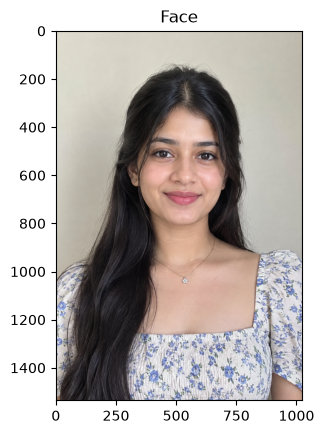

In [51]:
# Load the Face Image
faceImage = cv2.imread('08.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [52]:
faceImage.shape

(1536, 1024, 3)

In [53]:
#resized_faceImage.shape
faceImage.shape

(1536, 1024, 3)

Text(0.5, 1.0, 'glassPNG')

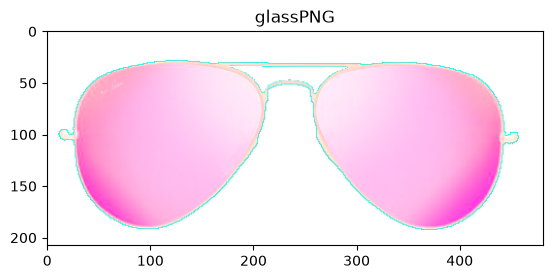

In [54]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [55]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(114,30))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(30, 114, 4)


In [56]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,:3]
glassMask = cv2.cvtColor(glassBGR,cv2.COLOR_BGR2GRAY)
glassMask = cv2.threshold(glassMask, 10, 225, cv2. THRESH_BINARY)[1]

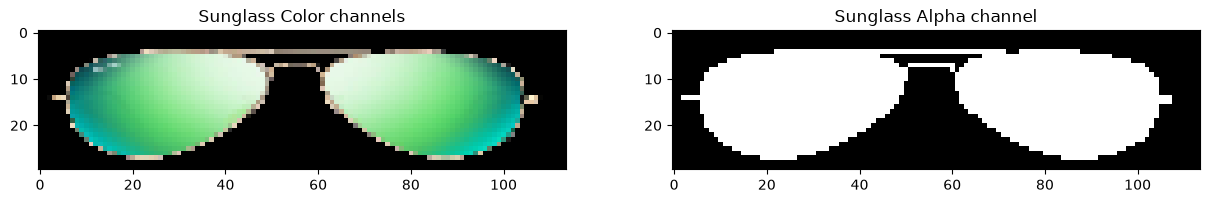

In [57]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask,cmap='gray');plt.title('Sunglass Alpha channel');

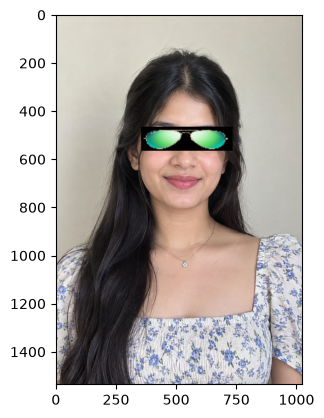

In [66]:
# Make a copy
#faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive = faceImage.copy()
glassResized = cv2.resize(glassBGR,(380, 100))

# Replace the eye region with the sunglass image
faceWithGlassesNaive[465:565 , 355:735]=glassResized

plt.imshow(faceWithGlassesNaive[...,::-1])

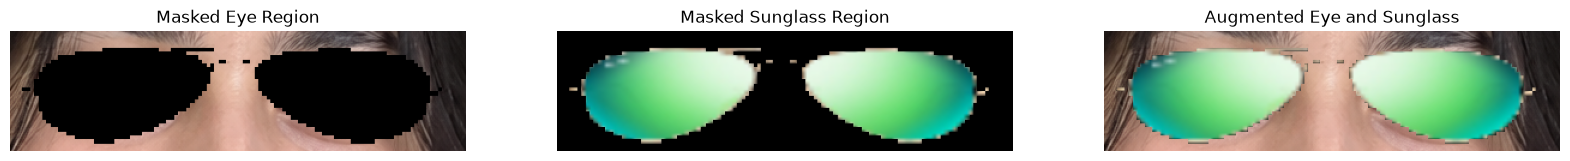

In [67]:
faceWithGlassesArithmetic = faceImage.copy()
eyeROI = faceWithGlassesArithmetic[465:565, 355:735]
glassResized = cv2.resize(glassBGR, (380, 100))
glassMask = glassPNG[:, :, 3]
glassMask = cv2.resize(glassMask,(380, 100),interpolation=cv2.INTER_NEAREST)
glassMask = np.uint8(glassMask > 127)
glassMask = cv2.merge((glassMask, glassMask, glassMask))
maskedEye = cv2.multiply(eyeROI,1 - glassMask)
maskedGlass = cv2.multiply(glassResized,glassMask)
eyeROIFinal = cv2.add(maskedEye,maskedGlass)
faceWithGlassesArithmetic[450:550,350:730] = eyeROIFinal
plt.figure(figsize=(20, 5))
plt.subplot(131)
plt.imshow(maskedEye[..., ::-1])
plt.title("Masked Eye Region")
plt.axis("off")
plt.subplot(132)
plt.imshow(maskedGlass[..., ::-1])
plt.title("Masked Sunglass Region")
plt.axis("off")
plt.subplot(133)
plt.imshow(eyeROIFinal[..., ::-1])
plt.title("Augmented Eye and Sunglass")
plt.axis("off")
plt.show()

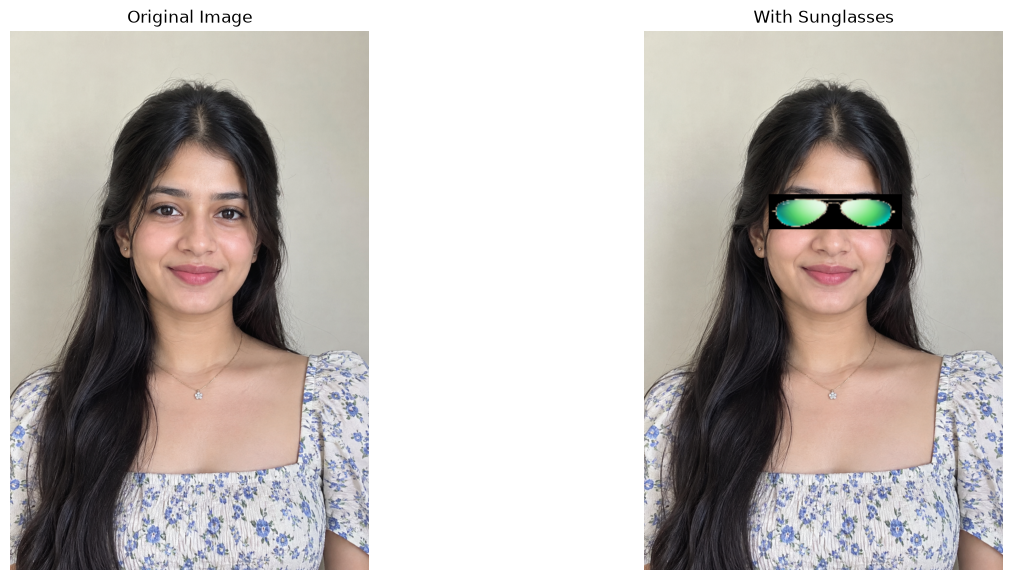

In [69]:
faceWithGlassesNaive = faceImage.copy()
glassResized = cv2.resize(glassBGR, (380, 100))
faceWithGlassesNaive[465:565, 355:735] = glassResized
plt.figure(figsize=(15, 7))
plt.subplot(121)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.subplot(122)
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("With Sunglasses")
plt.axis("off")
plt.show()